# Chatbots clássicos com PLN e Machine Learning

**Aluno: Tiago Galhardo Avelar**

**Tema:** reconhecimento de intenções em atendimento bancário usando **TF-IDF + SVM linear**.  
**Ambiente:** execução local em CPU.  
**Dados:** BANKING77 (inglês), com 77 intenções.

### Objetivos
1. Explicar como um chatbot de domínio fechado reconhece intenções.
2. Treinar e avaliar um classificador de intenções com Scikit-learn.
3. Conectar previsões a respostas predefinidas e implementar um fallback simples.
4. Investigar erros e limitações da abordagem clássica.

> **Importante:** este chatbot é uma demonstração didática. Não acessa contas, não realiza pagamentos e não executa operações bancárias.


## 1. Como funciona um chatbot clássico?

Considere a mensagem: **“I lost my card yesterday.”**

- **Intenção:** o objetivo do usuário; neste caso, comunicar a perda de um cartão.
- **Entidade:** detalhe extraído do texto, como *yesterday* (data relativa). **Este notebook classifica intenções; não treina um extrator de entidades.**
- **Gerenciamento de diálogo:** decide como o sistema deve prosseguir.
- **Resposta:** texto previamente associado à intenção prevista.

**Pipeline:** mensagem → TF-IDF → SVM linear → intenção → resposta cadastrada/fallback.

**Por que TF-IDF?** Converte o texto em um vetor numérico esparso. Um termo frequente em uma mensagem mas relativamente raro nos documentos do corpus ganha maior peso. Um **n-grama** representa uma sequência de *n* palavras: `(1, 2)` usa palavras isoladas e pares consecutivos.

**Por que SVM linear?** O `LinearSVC` aprende fronteiras lineares que separam as classes no espaço vetorial. É uma abordagem tradicional, rápida em bases moderadas e bastante adequada como baseline de classificação de texto. Ele não compreende linguagem como uma pessoa e não produz respostas espontaneamente.

## 2. Bibliotecas e reprodutibilidade

Usaremos bibliotecas amplamente disponíveis no Colab.

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Python:', sys.version.split()[0])
print('Scikit-learn:', sklearn.__version__)
print('Processamento: CPU; nenhuma GPU é necessária.')

Python: 3.12.10
Scikit-learn: 1.9.1
Processamento: CPU; nenhuma GPU é necessária.


## 3. Conhecendo o dataset BANKING77

O [BANKING77](https://github.com/PolyAI-LDN/task-specific-datasets) contém mensagens reais ou representativas de atendimento bancário, em inglês, rotuladas em 77 intenções. Utilizaremos a **divisão oficial de teste**, reservada até a avaliação final.

Os links apontam para arquivos CSV públicos do repositório da PolyAI. Para executar, é necessário acesso à internet somente no download inicial.

In [2]:
BASE_URL = 'https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data'
t0 = time.perf_counter()
train_raw = pd.read_csv(f'{BASE_URL}/train.csv')
test_df = pd.read_csv(f'{BASE_URL}/test.csv')

required = {'text', 'category'}
assert required.issubset(train_raw.columns) and required.issubset(test_df.columns), 'Colunas esperadas não encontradas.'
train_raw = train_raw[['text','category']].dropna().reset_index(drop=True)
test_df = test_df[['text','category']].dropna().reset_index(drop=True)
assert set(test_df['category']).issubset(set(train_raw['category'])), 'Existem categorias no teste ausentes no treino.'

print(f'Download e leitura: {time.perf_counter()-t0:.2f} s')
print(f'Exemplos oficiais — treino: {len(train_raw):,} | teste: {len(test_df):,}')
print(f'Intenções: {train_raw.category.nunique()}')
display(train_raw.sample(8, random_state=RANDOM_STATE))

Download e leitura: 2.48 s
Exemplos oficiais — treino: 10,003 | teste: 3,080
Intenções: 77


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer
5573,Why am I getting declines when trying to make ...,declined_transfer
576,What is the $1 transaction on my account?,extra_charge_on_statement
6832,It looks like my card payment was sent back.,reverted_card_payment?


### Divisão treino / validação / teste

A **validação** serve para analisar escolhas durante o desenvolvimento; o **teste** fornece a avaliação final e não deve ser usado para ajustar o modelo. A separação é estratificada, preservando aproximadamente a proporção de cada intenção.

,Conjunto,Exemplos,Intenções
0,Treinamento,8502,77
1,Validação,1501,77
2,Teste oficial,3080,77


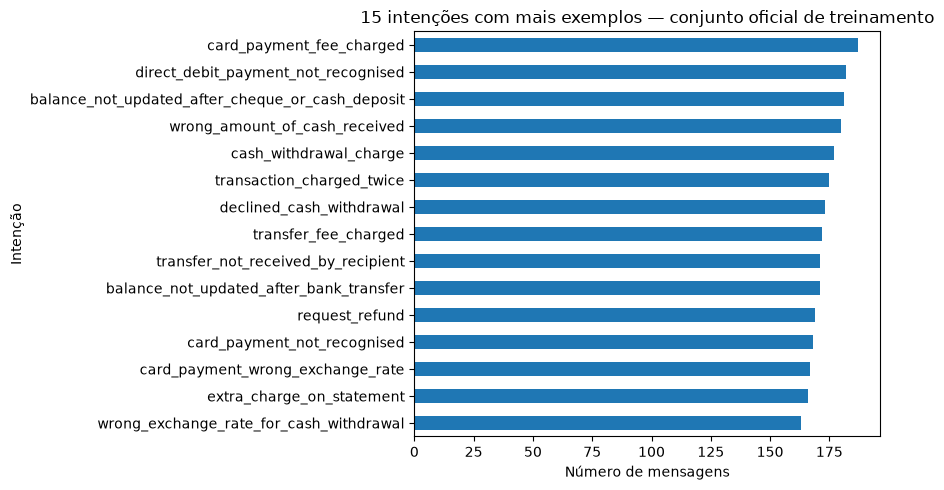

In [3]:
train_df, val_df = train_test_split(
    train_raw, test_size=0.15, random_state=RANDOM_STATE,
    stratify=train_raw['category']
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

splits = pd.DataFrame({
    'Conjunto': ['Treinamento', 'Validação', 'Teste oficial'],
    'Exemplos': [len(train_df), len(val_df), len(test_df)],
    'Intenções': [train_df.category.nunique(), val_df.category.nunique(), test_df.category.nunique()]
})
display(splits)

counts = train_raw.category.value_counts().head(15).sort_values()
ax = counts.plot.barh(figsize=(9,5), title='15 intenções com mais exemplos — conjunto oficial de treinamento')
ax.set_xlabel('Número de mensagens')
ax.set_ylabel('Intenção')
plt.tight_layout()
plt.show()

## 4. TF-IDF + SVM: treinamento

`Pipeline` é uma maneira segura de ajustar a transformação de texto **apenas nos dados de treinamento**, evitando vazamento de informação (*data leakage*). O pré-processamento para uma nova frase será idêntico ao do treinamento.

- `ngram_range=(1,2)`: unigramas e bigramas;
- `sublinear_tf=True`: substitui a frequência bruta por uma escala logarítmica;
- `LinearSVC`: classificador linear multiclasse.

O modelo usa **pesos aprendidos** e não regras manuais de correspondência de palavras.

In [4]:
def make_pipeline(ngram_range=(1,2)):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=ngram_range, sublinear_tf=True)),
        ('svm', LinearSVC(random_state=RANDOM_STATE, max_iter=3000))
    ])

model = make_pipeline()
t0 = time.perf_counter()
model.fit(train_df['text'], train_df['category'])
training_seconds = time.perf_counter() - t0

vocabulary_size = len(model.named_steps['tfidf'].vocabulary_)
print(f'Treinamento: {training_seconds:.2f} s')
print(f'Vocabulário TF-IDF (termos e n-gramas): {vocabulary_size:,}')
print(f'Intenções aprendidas: {len(model.classes_)}')

Treinamento: 2.47 s
Vocabulário TF-IDF (termos e n-gramas): 21,595
Intenções aprendidas: 77


## 5. Validação e avaliação final

**Métricas:**
- *Accuracy*: proporção de previsões corretas;
- *Precision macro*: precisão média entre as classes, com peso igual para cada intenção;
- *Recall macro*: sensibilidade média entre as classes;
- *F1 macro*: média dos F1 de cada classe.

**Atenção:** as métricas medem a identificação da intenção, **não** a qualidade de um diálogo completo.

In [5]:
def evaluate_classifier(trained_model, frame, split_name):
    t0 = time.perf_counter()
    pred = trained_model.predict(frame['text'])
    elapsed = time.perf_counter() - t0
    precision, recall, f1, _ = precision_recall_fscore_support(
        frame['category'], pred, average='macro', zero_division=0
    )
    metrics = {
        'Conjunto': split_name,
        'Accuracy': accuracy_score(frame['category'], pred),
        'Precision macro': precision,
        'Recall macro': recall,
        'F1 macro': f1,
        'Tempo total inferência (s)': elapsed,
        'ms/mensagem': elapsed * 1000 / len(frame)
    }
    return metrics, np.asarray(pred)

val_metrics, val_pred = evaluate_classifier(model, val_df, 'Validação')
test_metrics, test_pred = evaluate_classifier(model, test_df, 'Teste oficial')
metric_table = pd.DataFrame([val_metrics, test_metrics]).set_index('Conjunto')
display(metric_table.style.format({
    'Accuracy':'{:.3f}', 'Precision macro':'{:.3f}', 'Recall macro':'{:.3f}',
    'F1 macro':'{:.3f}', 'Tempo total inferência (s)':'{:.3f}',
    'ms/mensagem':'{:.3f}'
}))
print(f'Tempo de treinamento: {training_seconds:.2f} s')

,Accuracy,Precision macro,Recall macro,F1 macro,Tempo total inferência (s),ms/mensagem
Conjunto,,,,,,
Validação,0.889,0.898,0.891,0.891,0.050,0.033
Teste oficial,0.886,0.890,0.886,0.886,0.099,0.032


Tempo de treinamento: 2.47 s


### 5.1. Onde o classificador erra?

A seguir, identificamos as **10 classes verdadeiras com mais erros** no conjunto de teste. A matriz mostra apenas exemplos cujas classes verdadeiras e previstas pertencem a esse subconjunto; por isso, é **parcial** e não representa a matriz completa de 77 classes.

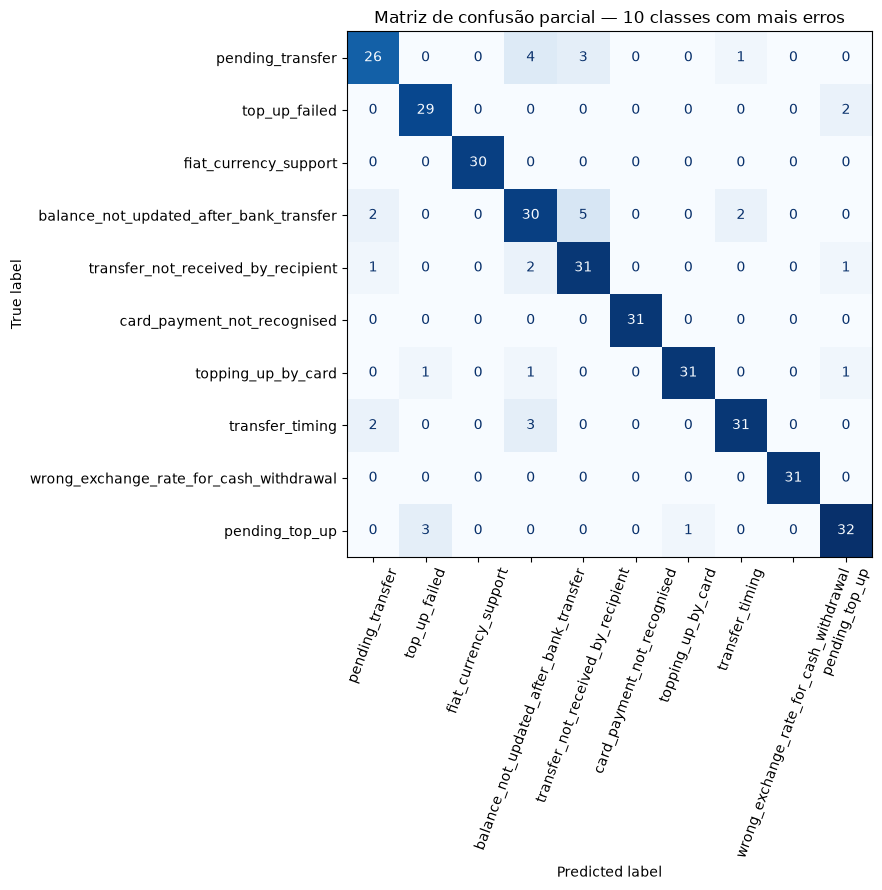

,Mensagem,Correta,Prevista
1347,Cannot access my top up.,topping_up_by_card,top_up_failed
3005,What do you need for my identity check?,verify_my_identity,why_verify_identity
2711,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer
2092,My card is being declined for a purchase. I bo...,reverted_card_payment?,top_up_failed
1332,how can i top up?,topping_up_by_card,top_up_limits
2503,can I have a non virtual card?,order_physical_card,getting_virtual_card
2664,can you check why I wasn't able to top up?,top_up_failed,top_up_by_cash_or_cheque
2048,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer
2525,Why is my virtual card is being declined?,virtual_card_not_working,getting_virtual_card
1626,"I was double charged, and the second charge is...",pending_card_payment,transaction_charged_twice


Erros totais no teste: 351 de 3080.


In [6]:
errors_df = test_df.copy()
errors_df['prediction'] = test_pred
errors_df['wrong'] = errors_df['category'] != errors_df['prediction']

worst_classes = (errors_df.loc[errors_df.wrong, 'category']
                 .value_counts().head(10).index.tolist())
mask = errors_df['category'].isin(worst_classes) & errors_df['prediction'].isin(worst_classes)
cm = confusion_matrix(errors_df.loc[mask,'category'],
                      errors_df.loc[mask,'prediction'], labels=worst_classes)
fig, ax = plt.subplots(figsize=(11,9))
ConfusionMatrixDisplay(cm, display_labels=worst_classes).plot(
    ax=ax, xticks_rotation=70, cmap='Blues', colorbar=False, values_format='d'
)
ax.set_title('Matriz de confusão parcial — 10 classes com mais erros')
plt.tight_layout()
plt.show()

examples = (errors_df.loc[errors_df.wrong, ['text','category','prediction']]
            .sample(n=min(10, int(errors_df.wrong.sum())), random_state=RANDOM_STATE)
            .rename(columns={'text':'Mensagem','category':'Correta','prediction':'Prevista'}))
display(examples)
print(f'Erros totais no teste: {errors_df.wrong.sum()} de {len(errors_df)}.')

### 5.2. Inspecionando a representação numérica

Veja quais n-gramas do texto de exemplo estão presentes no vocabulário do TF-IDF. Isso ajuda a entender que o classificador opera sobre **atributos numéricos esparsos**, não sobre uma interpretação explícita da intenção.

In [7]:
example = 'I lost my bank card and need a replacement'
vectorizer = model.named_steps['tfidf']
vec = vectorizer.transform([example])
feature_names = vectorizer.get_feature_names_out()
active = sorted(zip(feature_names[vec.indices], vec.data), key=lambda x: -x[1])
print('Exemplo:', example)
print('Atributos não nulos:', vec.nnz)
display(pd.DataFrame(active[:15], columns=['Termo ou n-grama', 'Peso TF-IDF']))

Exemplo: I lost my bank card and need a replacement
Atributos não nulos: 12


,Termo ou n-grama,Peso TF-IDF
0,replacement,0.401792
1,bank card,0.389127
2,my bank,0.365388
3,lost my,0.327804
4,and need,0.325520
5,card and,0.309305
6,lost,0.290246
7,bank,0.265632
8,need,0.195763
9,and,0.168073


## 6. Construindo o chatbot

O SVM reconhece **intenções**, mas não escreve respostas. Adicionaremos uma pequena camada de diálogo que consulta um catálogo de respostas.

Este exemplo **não extrai entidades**, **não armazena contexto entre turnos** e **não executa transações**. Um chatbot real precisaria desses recursos, além de autenticação e integrações seguras.

**Fallback:** o `LinearSVC` fornece *margens de decisão* via `decision_function`, **não probabilidades**. Usaremos a maior margem como um sinal heurístico para rejeitar entradas pouco familiares. O limiar será calibrado **somente na validação**, com foco em detectar previsões incorretas conhecidas. Esse mecanismo **não garante** detectar mensagens fora do domínio.

In [8]:
# Conferimos os nomes das intenções disponíveis antes de cadastrar respostas.
all_labels = set(model.classes_)
responses = {
    'lost_or_stolen_card': 'I can guide you to report a lost or stolen card. Please use the official banking app or contact your bank immediately.',
    'card_not_working': 'Please check the card status in the official app. If the issue persists, contact the bank support team.',
    "card_arrival": "You can usually check card delivery and tracking details through your bank's official app.",
    'card_linking': 'Check the card section of the banking app for instructions to link your card.',
    'cash_withdrawal_charge': 'Please review the cash withdrawal fee information in the official pricing documents.',
    'pending_cash_withdrawal': 'A pending withdrawal may take time to appear. Check the official transaction status.',
    'beneficiary_not_allowed': 'Please verify the beneficiary details and contact official support if the transfer remains blocked.',
    'cancel_transfer': 'Transfer cancellation depends on its status. Check the official app or contact support promptly.',
    'pending_transfer': 'Please check the transfer status in the official banking app.',
    'failed_transfer': 'Check the destination details and error shown in the official banking app.',
    'card_payment_wrong_exchange_rate': 'Check the exchange-rate information in your payment details and bank terms.',
    'declined_card_payment': 'Check your card settings and available balance; contact the bank if the payment is still declined.',
    "getting_virtual_card": "You can find information about virtual card availability in the bank's official app.",
    'change_pin': 'Check the official app for options to change your card PIN; do not share your PIN here.',
    'verify_my_identity': 'Identity verification should be completed only through official secure banking channels.',
    'extra_charge_on_statement': 'Review your statement and contact the bank if you do not recognize a charge.'
}
responses = {k:v for k,v in responses.items() if k in all_labels}
print(f'Respostas específicas configuradas para {len(responses)} das {len(all_labels)} intenções.')
print('Categorias com resposta:', ', '.join(sorted(responses)))

Respostas específicas configuradas para 16 das 77 intenções.
Categorias com resposta: beneficiary_not_allowed, cancel_transfer, card_arrival, card_linking, card_not_working, card_payment_wrong_exchange_rate, cash_withdrawal_charge, change_pin, declined_card_payment, extra_charge_on_statement, failed_transfer, getting_virtual_card, lost_or_stolen_card, pending_cash_withdrawal, pending_transfer, verify_my_identity


### 6.1. Selecionando um limiar de fallback (somente validação)

Para uma demonstração simples, selecionamos um limiar entre quantis das margens observadas na validação. O critério busca **reter a maior cobertura de previsões possível**, exigindo precisão de pelo menos 90% entre as previsões aceitas; se nenhum limiar satisfizer a meta, o código escolhe o que maximiza a precisão observada. Trata-se de uma heurística experimental, **não de confiança probabilística calibrada**.

A avaliação oficial de acurácia/F1 anterior continua sendo a do classificador **sem rejeição**.

In [9]:
def max_margin(trained_model, texts):
    scores = trained_model.decision_function(texts)
    return np.max(scores, axis=1)

val_margins = max_margin(model, val_df['text'])
correct = np.asarray(val_pred) == val_df['category'].to_numpy()
quantiles = np.unique(np.quantile(val_margins, np.linspace(0, 0.95, 40)))
rows = []
for t in quantiles:
    accepted = val_margins >= t
    if accepted.any():
        rows.append({'threshold':float(t), 'coverage':float(accepted.mean()),
                     'accepted_accuracy':float(correct[accepted].mean())})
threshold_df = pd.DataFrame(rows)
feasible = threshold_df[threshold_df.accepted_accuracy >= 0.90]
if len(feasible):
    choice = feasible.sort_values(['coverage','accepted_accuracy'], ascending=False).iloc[0]
else:
    choice = threshold_df.sort_values(['accepted_accuracy','coverage'], ascending=False).iloc[0]
FALLBACK_THRESHOLD = float(choice.threshold)
print(f'Limiar escolhido: {FALLBACK_THRESHOLD:.3f}')
print(f'Cobertura estimada na validação: {choice.coverage:.1%}')
print(f'Acurácia nas previsões aceitas (validação): {choice.accepted_accuracy:.1%}')
print('ATENÇÃO: margem de decisão NÃO é probabilidade; OOD continua difícil.')

Limiar escolhido: -0.555
Cobertura estimada na validação: 97.5%
Acurácia nas previsões aceitas (validação): 90.1%
ATENÇÃO: margem de decisão NÃO é probabilidade; OOD continua difícil.


In [10]:
class ClassicChatbot:
    def __init__(self, classifier, response_map, threshold):
        self.classifier = classifier
        self.response_map = response_map
        self.threshold = float(threshold)

    def respond(self, message: str) -> dict:
        if not isinstance(message, str) or not message.strip():
            return {'message': message, 'intent': None,
                    'response': 'Please type a banking question in English.',
                    'fallback': True, 'decision_score': None}
        intent = str(self.classifier.predict([message])[0])
        score = float(max_margin(self.classifier, [message])[0])
        low_margin = score < self.threshold
        if low_margin:
            response = ('I am not sure what you mean. Please rephrase your question '
                        'or contact the bank through an official channel.')
        elif intent in self.response_map:
            response = self.response_map[intent]
        else:
            response = (f'I understood your question as: {intent.replace("_", " ")}. '
                        'However, I do not have a specific procedure configured for it.')
        return {'message': message, 'intent': intent, 'response': response,
                'fallback': bool(low_margin or intent not in self.response_map),
                'decision_score': score}

bot = ClassicChatbot(model, responses, FALLBACK_THRESHOLD)
print(bot.respond('My card is missing. What should I do?'))

{'message': 'My card is missing. What should I do?', 'intent': 'lost_or_stolen_card', 'response': 'I can guide you to report a lost or stolen card. Please use the official banking app or contact your bank immediately.', 'fallback': False, 'decision_score': 0.19123370143077079}


## 7. Testes do chatbot

Teste mensagens mais simples, paráfrases, erros de digitação, entradas ambíguas e mensagens fora do domínio. **Se o chatbot classificar uma frase sobre culinária como um problema bancário, isso demonstra uma limitação de classificadores de conjunto fechado.**

In [11]:
test_messages = [
    'I lost my bank card',
    'My card has not arrived yet',
    'I cannot pay with my card',
    'How can I change my PIN?',
    'My transfer is still pending',
    'Please cancel the money transfer',
    'I was charged twice for a purchase',
    'My crad is not wrking',              # erro de digitação
    'Something is wrong with my money',  # ambígua
    'What is the best pasta recipe?',    # fora do domínio
    'Tell me a joke about dinosaurs',    # fora do domínio
    'Can you explain quantum physics?'   # fora do domínio
]
results = [bot.respond(m) for m in test_messages]
display(pd.DataFrame(results)[['message','intent','fallback','decision_score','response']])

,message,intent,fallback,decision_score,response
0,I lost my bank card,lost_or_stolen_card,False,-0.003771,I can guide you to report a lost or stolen car...
1,My card has not arrived yet,card_arrival,False,-0.081261,You can usually check card delivery and tracki...
2,I cannot pay with my card,card_acceptance,True,-0.045178,I understood your question as: card acceptance...
3,How can I change my PIN?,change_pin,False,1.574437,Check the official app for options to change y...
4,My transfer is still pending,pending_transfer,False,1.275417,Please check the transfer status in the offici...
5,Please cancel the money transfer,cancel_transfer,False,0.451110,Transfer cancellation depends on its status. C...
6,I was charged twice for a purchase,transaction_charged_twice,True,1.386571,I understood your question as: transaction cha...
7,My crad is not wrking,Refund_not_showing_up,True,-0.612447,I am not sure what you mean. Please rephrase y...
8,Something is wrong with my money,declined_cash_withdrawal,True,-0.217054,I understood your question as: declined cash w...
9,What is the best pasta recipe?,exchange_rate,True,-0.469181,I understood your question as: exchange rate. ...


### 7.1. Converse com o modelo

Execute a célula abaixo e digite uma pergunta em inglês. O campo de entrada é controlado pelo Colab; a biblioteca de widgets costuma estar disponível, mas a célula também oferece uma função simples que pode ser chamada manualmente.

In [12]:
def chat(message):
    result = bot.respond(message)
    print('Você:', result['message'])
    print('Intenção:', result['intent'])
    print('Margem de decisão (não é probabilidade):', result['decision_score'])
    print('Fallback:', result['fallback'])
    print('Chatbot:', result['response'])
    return result

# Alternativa universal: chame chat('My card is missing') em outra célula.
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    entry = widgets.Text(placeholder='Type a banking message in English...',
                         description='Mensagem:', layout=widgets.Layout(width='80%'))
    send = widgets.Button(description='Enviar', button_style='primary')
    output = widgets.Output()
    def on_send(_):
        with output:
            clear_output(wait=True)
            chat(entry.value)
    send.on_click(on_send)
    display(widgets.VBox([entry, send, output]))
except ImportError:
    print("Widgets indisponíveis. Use chat('My card is missing') em uma nova célula.")

Widgets indisponíveis. Use chat('My card is missing') em uma nova célula.


## 8. Discussão: o que este chatbot consegue e o que não consegue?

**Pontos fortes:** treinamento rápido em CPU; resultados mensuráveis; respostas controladas; implementação clara; dispensa modelos grandes.

**Limitações:**
1. **Representação lexical:** TF-IDF não incorpora diretamente o contexto semântico profundo de uma frase.
2. **Conjunto fechado de intenções:** o classificador sempre prevê uma das 77 classes antes da regra de fallback, mesmo para mensagens que não são bancárias.
3. **Fallback heurístico:** margens de `LinearSVC` não são probabilidades e não garantem detecção de entradas fora do domínio.
4. **Sem memória de diálogo:** a implementação analisa cada mensagem de forma independente; não resolve referências como *“And what about tomorrow?”* a um turno anterior.
5. **Sem geração de texto nem ações externas:** as respostas são predefinidas; nenhuma operação real é executada.
6. **Idioma:** o conjunto de treino está em inglês; resultados em português são imprevisíveis.

**Para comparação com BERT:** utilizar os mesmos conjuntos de treino, validação e teste e as mesmas métricas. Assim, as diferenças observadas refletem principalmente o uso de representações contextuais e de pré-treinamento, além das demais diferenças entre os modelos.

## 9. Atividades -- Notebook Extra 2.1

Quem entregar essa atividade (Extra 2.1) E a atividade do Notebook Extra 2.2, e ter uma nota média (entre as duas atividades Extra 2.1 e 2.2) maior que uma nota menor de outro notebook, terá a nota menor substituida. Isso vale para demais notebooks fora o Notebook Extra e o primeiro notebook com nota substituida.

### Exercício 1 — Unigramas vs. unigramas + bigramas
Treine outro `Pipeline` usando `ngram_range=(1,1)` e compare Accuracy, F1 macro e tempo de treinamento **na validação**. Não use o teste para escolher o melhor modelo.

### Exercício 2 — Fallback fora do domínio
Compare o comportamento do chatbot para pelo menos cinco mensagens que não mencionem serviços bancários. Quantas foram rejeitadas? Explique por que uma margem alta não implica que a intenção esteja correta.

### Exercício 3 — Análise de erros
Selecione três exemplos errados, examine as duas intenções envolvidas e proponha uma mudança nos dados ou no modelo que possa reduzir a confusão.


In [13]:
# EXERCÍCIO 1 — unigramas vs. unigramas + bigramas
unigram_model = make_pipeline(ngram_range=(1, 1))
t0 = time.perf_counter()
unigram_model.fit(train_df['text'], train_df['category'])
unigram_train_seconds = time.perf_counter() - t0
unigram_metrics, unigram_val_pred = evaluate_classifier(
    unigram_model, val_df, 'Unigramas (validação)'
)

comparison = pd.DataFrame([
    {
        'Modelo': 'TF-IDF (1,2) + LinearSVC',
        'Accuracy': val_metrics['Accuracy'],
        'F1 macro': val_metrics['F1 macro'],
        'Treino (s)': training_seconds,
        'Vocabulário': len(model.named_steps['tfidf'].vocabulary_),
    },
    {
        'Modelo': 'TF-IDF (1,1) + LinearSVC',
        'Accuracy': unigram_metrics['Accuracy'],
        'F1 macro': unigram_metrics['F1 macro'],
        'Treino (s)': unigram_train_seconds,
        'Vocabulário': len(unigram_model.named_steps['tfidf'].vocabulary_),
    },
])
display(comparison.style.format({
    'Accuracy': '{:.3f}', 'F1 macro': '{:.3f}', 'Treino (s)': '{:.3f}',
    'Vocabulário': '{:,.0f}'
}))

best_row = comparison.sort_values(['F1 macro', 'Accuracy'], ascending=False).iloc[0]
print('Melhor representação na validação:', best_row['Modelo'])
print(
    'Interpretação: bigramas podem capturar expressões como "cash withdrawal" e '
    '"card payment", mas aumentam o vocabulário e o custo. O resultado observado '
    'na validação determina se esse contexto adicional compensou a maior dimensionalidade.'
)

assert comparison.shape[0] == 2
assert comparison[['Accuracy', 'F1 macro']].notna().all().all()


,Modelo,Accuracy,F1 macro,Treino (s),Vocabulário
0,"TF-IDF (1,2) + LinearSVC",0.889,0.891,2.468,"21,595"
1,"TF-IDF (1,1) + LinearSVC",0.896,0.895,0.747,"2,178"


Melhor representação na validação: TF-IDF (1,1) + LinearSVC
Interpretação: bigramas podem capturar expressões como "cash withdrawal" e "card payment", mas aumentam o vocabulário e o custo. O resultado observado na validação determina se esse contexto adicional compensou a maior dimensionalidade.


### Exercício 2 — Fallback fora do domínio

As mensagens abaixo não mencionam serviços bancários. Medimos quantas recebem fallback e também inspecionamos a margem máxima. Uma margem alta significa apenas que, entre as 77 fronteiras aprendidas, uma classe ficou relativamente mais distante das demais; ela não é probabilidade nem prova de que a entrada pertença ao domínio bancário.


In [14]:
out_of_domain_messages = [
    'What is the best recipe for chocolate cake?',
    'Tell me a joke about dinosaurs.',
    'Will it rain tomorrow in London?',
    'How do I train for a marathon?',
    'Explain quantum entanglement to me.',
    'Who won the football match yesterday?',
    'Recommend a science fiction movie.',
    'How can I grow tomatoes at home?',
]

ood_results = pd.DataFrame([bot.respond(message) for message in out_of_domain_messages])
display(ood_results[['message', 'intent', 'fallback', 'decision_score', 'response']])

rejected_ood = int(ood_results['fallback'].sum())
total_ood = len(ood_results)
print(f'Mensagens fora do domínio rejeitadas: {rejected_ood}/{total_ood} ({rejected_ood/total_ood:.1%})')
print(
    'Uma margem alta não garante correção: o LinearSVC sempre compara a entrada '
    'com classes bancárias conhecidas e pode ficar muito seguro por coincidências '
    'lexicais, mesmo quando nenhuma intenção é semanticamente adequada.'
)

assert total_ood >= 5
assert 0 <= rejected_ood <= total_ood


,message,intent,fallback,decision_score,response
0,What is the best recipe for chocolate cake?,exchange_rate,True,-0.566077,I am not sure what you mean. Please rephrase y...
1,Tell me a joke about dinosaurs.,get_disposable_virtual_card,True,-0.685236,I am not sure what you mean. Please rephrase y...
2,Will it rain tomorrow in London?,automatic_top_up,True,-0.820837,I am not sure what you mean. Please rephrase y...
3,How do I train for a marathon?,verify_my_identity,False,-0.065142,Identity verification should be completed only...
4,Explain quantum entanglement to me.,receiving_money,True,-0.564303,I am not sure what you mean. Please rephrase y...
5,Who won the football match yesterday?,cancel_transfer,True,-0.770296,I am not sure what you mean. Please rephrase y...
6,Recommend a science fiction movie.,transaction_charged_twice,True,-0.922501,I am not sure what you mean. Please rephrase y...
7,How can I grow tomatoes at home?,verify_my_identity,True,-0.731153,I am not sure what you mean. Please rephrase y...


Mensagens fora do domínio rejeitadas: 7/8 (87.5%)
Uma margem alta não garante correção: o LinearSVC sempre compara a entrada com classes bancárias conhecidas e pode ficar muito seguro por coincidências lexicais, mesmo quando nenhuma intenção é semanticamente adequada.


### Exercício 3 — Análise de três erros

Agrupamos os erros do teste pelo par `(intenção correta, intenção prevista)`, selecionamos as três confusões mais frequentes e mostramos uma mensagem real de cada par. A coluna de proposta registra uma intervenção possível nos dados ou no modelo.


In [15]:
confusion_pairs = (
    errors_df.loc[errors_df.wrong]
    .groupby(['category', 'prediction'])
    .size()
    .sort_values(ascending=False)
    .head(3)
)

analysis_rows = []
for (correct_intent, predicted_intent), count in confusion_pairs.items():
    example_row = errors_df[
        (errors_df['category'] == correct_intent)
        & (errors_df['prediction'] == predicted_intent)
    ].iloc[0]
    analysis_rows.append({
        'Mensagem': example_row['text'],
        'Intenção correta': correct_intent,
        'Intenção prevista': predicted_intent,
        'Ocorrências do par': int(count),
        'Proposta': (
            'Adicionar exemplos contrastivos e hard negatives das duas intenções; '
            'avaliar n-gramas de caracteres para variações lexicais e comparar com '
            'um encoder contextual mantendo a mesma divisão de dados.'
        ),
    })

error_analysis = pd.DataFrame(analysis_rows)
display(error_analysis)
print(
    'Interpretação: as classes confundidas costumam compartilhar vocabulário '
    'bancário. TF-IDF representa coincidências lexicais, mas não modela bem contexto, '
    'relações entre eventos ou diferenças sutis de estado e finalidade.'
)

assert len(error_analysis) == 3
assert error_analysis[['Intenção correta', 'Intenção prevista']].notna().all().all()


,Mensagem,Intenção correta,Intenção prevista,Ocorrências do par,Proposta
0,I'd rather not verify my identity.,why_verify_identity,verify_my_identity,6,Adicionar exemplos contrastivos e hard negativ...
1,I didn't get the money I transferred,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,5,Adicionar exemplos contrastivos e hard negativ...
2,Why didn`t my topup go through?,top_up_failed,top_up_reverted,5,Adicionar exemplos contrastivos e hard negativ...


Interpretação: as classes confundidas costumam compartilhar vocabulário bancário. TF-IDF representa coincidências lexicais, mas não modela bem contexto, relações entre eventos ou diferenças sutis de estado e finalidade.


## 9.1. Síntese das atividades

O experimento principal mede o classificador em validação e teste oficial. O Exercício 1 usa somente a validação para comparar representações. O Exercício 2 mostra que rejeição por margem é uma heurística imperfeita para entradas fora do domínio. O Exercício 3 evidencia confusões entre intenções lexicalmente próximas e sugere dados contrastivos, robustez ortográfica e modelos contextuais como possíveis melhorias.


## 10. Referências, créditos e resposta de fechamento

- **BANKING77:** [PolyAI — Task-specific datasets](https://github.com/PolyAI-LDN/task-specific-datasets); Casanueva et al., [*Efficient Intent Detection with Dual Sentence Encoders*](https://aclanthology.org/2020.nlp4convai-1.5/) (2020).
- **Scikit-learn:** [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).
- **Notebook-modelo:** arquivo público fornecido na atividade Extra 2.1.
- **Jupyter nbclient:** [execução programática de notebooks](https://nbclient.readthedocs.io/).

### Pergunta de fechamento

Um resultado alto na classificação das 77 intenções **não significa necessariamente** que foi construído um bom chatbot. Accuracy e F1 medem a escolha de um rótulo para mensagens isoladas e pertencentes ao domínio conhecido. O sucesso de uma conversa também depende de detectar mensagens fora do domínio, extrair entidades, manter contexto entre turnos, esclarecer ambiguidades, fornecer respostas úteis, proteger dados, integrar serviços com segurança e permitir encaminhamento para atendimento humano. Portanto, o classificador é apenas um componente do sistema conversacional.


# Comentários

---
**Comentários:**

Ferramenta: OpenAI Codex (modelo GPT-5)

Utilização: Utilizado como apoio para interpretar o notebook-modelo, completar os experimentos de unigramas e bigramas, implementar e revisar os testes de fallback, estruturar a análise de erros, documentar referências e validar as evidências executadas.

Ferramenta: scikit-learn

Utilização: Utilizado para TF-IDF, pipelines, treinamento do LinearSVC, divisão estratificada e métricas de avaliação.

Ferramenta: pandas e NumPy

Utilização: Utilizados para organização dos conjuntos, tabelas comparativas, análise de margens, contagem de erros e consolidação dos resultados.

Ferramenta: Matplotlib

Utilização: Utilizado para os gráficos de distribuição das intenções e matriz de confusão parcial.

Ferramenta: Jupyter Notebook / nbclient

Utilização: Utilizado para executar todas as células e registrar as evidências no arquivo entregue.
---


In [16]:
print("Notebook Extra 2.1 concluído e validado.")


Notebook Extra 2.1 concluído e validado.
